# HU-07 · Evaluación del recomendador

Fase 4 de HU-07. Evalúa el recomendador **tal como está implementado en Django**
(`appPrincipal/recomendaciones.py`), no una copia, con dos mediciones fuera de línea:

1. **Coherencia de los productos similares** de la ficha: qué porcentaje de las recomendaciones comparte
   plataforma o género con el producto, comparado con lo que mostraba la ficha antes de HU-07 («misma
   categoría» y «aleatorios»).
2. **Precisión con clientes simulados** (precision@5): clientes generados con Faker que tienen una
   preferencia oculta y navegan según reglas simples; se mide cuántas de sus 5 recomendaciones calzan con
   esa preferencia, comparado con «lo más vendido» y con recomendaciones al azar.

La tercera medición, el **KPI-05 real** (tasa de clics), se obtiene con clientes reales después de publicar
el sitio y se ve en el panel, en Configuración.

**Reproducibilidad:** el notebook crea una base de datos de prueba temporal (como los tests), carga el
catálogo de `appPrincipal/fixtures/catalogo.csv` con `seed_catalogo` y la elimina al final. No lee ni modifica
la base de datos de desarrollo, y las semillas aleatorias están fijas, así que cualquiera obtiene los mismos
números. Faker se usa solo para los clientes, nunca para los productos.

In [1]:
import os
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
os.environ.setdefault('DJANGO_SETTINGS_MODULE', 'Akaispace.settings')
os.environ['DJANGO_ALLOW_ASYNC_UNSAFE'] = 'true'  # Jupyter corre dentro de un event loop

import django
django.setup()

from django.contrib.auth.models import AnonymousUser
from django.core.management import call_command
from django.db import connection, transaction
from django.utils import timezone
from faker import Faker

from appPrincipal.models import InteraccionProducto, Producto, ProductoVenta, Usuario, Venta
from appPrincipal.recomendaciones import recomendar

SEMILLA = 2026
CANTIDAD = 5  # precision@5

# colores: HU-07 en azul; las alternativas en los colores siguientes de la paleta categórica
TINTA, TINTA_SECUNDARIA, SUPERFICIE, GRILLA = '#0b0b0b', '#52514e', '#fcfcfb', '#e4e3df'
COLORES = {'HU-07': '#2a78d6', 'Lo más vendido': '#eb6834', 'Al azar': '#1baf7a'}
GRIS = '#a3a29c'
plt.rcParams.update({
    'figure.facecolor': SUPERFICIE, 'axes.facecolor': SUPERFICIE, 'savefig.facecolor': SUPERFICIE,
    'text.color': TINTA, 'axes.labelcolor': TINTA_SECUNDARIA, 'axes.edgecolor': '#c3c2b7',
    'xtick.color': TINTA_SECUNDARIA, 'ytick.color': TINTA_SECUNDARIA,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
})

In [2]:
# base de datos de prueba temporal con el catálogo del CSV (seed_catalogo también calcula las similitudes)
nombre_base_desarrollo = connection.settings_dict['NAME']
connection.creation.create_test_db(verbosity=0, autoclobber=True, serialize=False)
call_command('seed_catalogo', verbosity=0)
assert connection.settings_dict['NAME'] != nombre_base_desarrollo

productos = list(Producto.objects.select_related('categoria', 'plataforma', 'genero').order_by('id'))
con_stock = [p for p in productos if p.stock > 0]
juegos = [p for p in productos if p.categoria.nombre == 'Videojuegos']
print(f'Base de prueba: {connection.settings_dict["NAME"]}')
print(f'{len(productos)} productos ({len(juegos)} videojuegos), {len(con_stock)} con stock')

Base de prueba: test_db_akaispace
115 productos (89 videojuegos), 113 con stock


## 1. Coherencia de los productos similares (ficha del producto)

Para cada videojuego del catálogo se toman las 4 recomendaciones de la ficha con cada método:

- **HU-07:** los productos similares (TF-IDF y similitud del coseno), lo que ve un visitante anónimo.
- **Misma categoría (antes):** 4 productos al azar de la misma categoría y plataforma, como hacía la ficha
  con la opción «De la misma categoría».
- **Aleatorios (antes):** 4 productos al azar de toda la tienda, como la opción «Aleatorios».

Los métodos al azar se repiten 30 veces con semillas distintas y se promedian. Para cada producto
recomendado se mide si comparte la plataforma, la familia, el género, o la plataforma **y** el género.
También se mide la **cobertura**: qué porcentaje de los videojuegos aparece en al menos una recomendación
(un recomendador que siempre muestra los mismos productos tendría cobertura baja).

In [3]:
REPETICIONES = 30


def similares_hu07(producto, rng):
    return recomendar(AnonymousUser(), producto, cantidad=4).productos


def misma_categoria(producto, rng):
    candidatos = [p for p in con_stock if p.id != producto.id and p.categoria_id == producto.categoria_id
                  and p.plataforma_id == producto.plataforma_id]
    return rng.sample(candidatos, min(4, len(candidatos)))


def aleatorios(producto, rng):
    candidatos = [p for p in con_stock if p.id != producto.id]
    return rng.sample(candidatos, 4)


def comparar(origen, recomendado):
    familia = lambda p: p.plataforma.familia if p.plataforma_id else None
    return {
        'misma plataforma': recomendado.plataforma_id == origen.plataforma_id,
        'misma familia': familia(recomendado) == familia(origen),
        'mismo género': recomendado.genero_id == origen.genero_id,
        'plataforma o género': (recomendado.plataforma_id == origen.plataforma_id
                                or recomendado.genero_id == origen.genero_id),
        'plataforma y género': (recomendado.plataforma_id == origen.plataforma_id
                                and recomendado.genero_id == origen.genero_id),
    }


metodos = {'HU-07 (similares)': (similares_hu07, 1), 'Misma categoría (antes)': (misma_categoria, REPETICIONES),
           'Aleatorios (antes)': (aleatorios, REPETICIONES)}
filas, cobertura = [], {}
for metodo, (funcion, repeticiones) in metodos.items():
    recomendados_alguna_vez = set()
    for repeticion in range(repeticiones):
        rng = random.Random(SEMILLA + repeticion)
        for juego in juegos:
            recomendados = funcion(juego, rng)
            recomendados_alguna_vez.update(p.id for p in recomendados if p.categoria_id == juego.categoria_id)
            for recomendado in recomendados:
                filas.append({'método': metodo, **comparar(juego, recomendado)})
    cobertura[metodo] = len(recomendados_alguna_vez) / len(juegos)

coherencia = pd.DataFrame(filas).groupby('método', sort=False).mean()
coherencia['cobertura de videojuegos'] = pd.Series(cobertura)
coherencia.map('{:.1%}'.format)

,misma plataforma,misma familia,mismo género,plataforma o género,plataforma y género,cobertura de videojuegos
método,,,,,,
HU-07 (similares),75.6%,88.5%,73.3%,100.0%,48.9%,94.4%
Misma categoría (antes),100.0%,100.0%,12.6%,100.0%,12.6%,100.0%
Aleatorios (antes),18.2%,30.3%,9.9%,26.2%,1.8%,100.0%


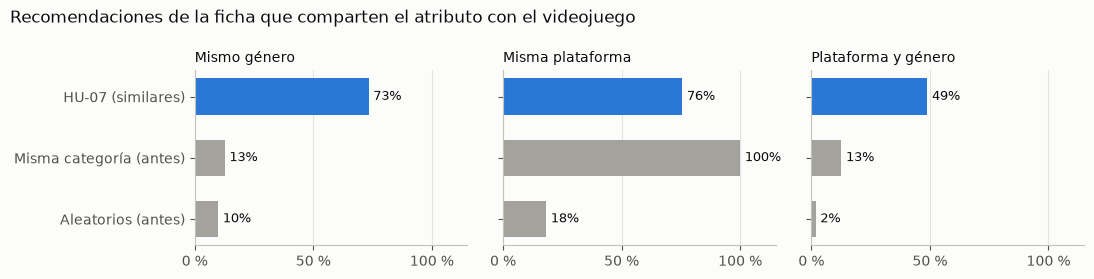

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(11, 2.8), sharey=True)
for eje, metrica in zip(ejes, ['mismo género', 'misma plataforma', 'plataforma y género']):
    valores = coherencia[metrica]
    colores = [COLORES['HU-07'] if metodo.startswith('HU-07') else GRIS for metodo in valores.index]
    eje.barh(valores.index, valores, color=colores, height=0.6)
    eje.invert_yaxis()
    eje.set_xlim(0, 1.15)
    eje.set_xticks([0, 0.5, 1], ['0 %', '50 %', '100 %'])
    eje.set_title(metrica.capitalize(), loc='left', fontsize=10)
    eje.grid(axis='x', color=GRILLA, linewidth=0.8)
    eje.set_axisbelow(True)
    for i, valor in enumerate(valores):
        eje.text(valor + 0.02, i, f'{valor:.0%}', va='center', fontsize=9, color=TINTA)
fig.suptitle('Recomendaciones de la ficha que comparten el atributo con el videojuego', x=0.01, ha='left',
             fontsize=12)
plt.tight_layout()
plt.show()

## 2. Precisión con clientes simulados (precision@5)

**Clientes simulados.** Se generan 200 clientes con Faker (nombre y correo chilenos, `es_CL`) que
autorizaron sus datos de navegación. Cada uno tiene una **preferencia oculta**: una plataforma, elegida
con la misma proporción de videojuegos que tiene cada plataforma en el catálogo, y uno o dos géneros
favoritos entre los que existen para esa plataforma.

**Navegación según reglas.** Cada cliente hace 10 interacciones. En cada una elige qué ficha ver:

- 70 %: un videojuego de su preferencia (su plataforma y uno de sus géneros) que aún no ha visto;
- 20 %: cualquier producto de su plataforma (otro género, una consola o un accesorio);
- 10 %: cualquier producto de la tienda (ruido).

Después de ver la ficha, con probabilidad 25 % lo agrega al carrito y con 10 % lo compra.

**Qué es acertar.** Una recomendación es **relevante** si es un videojuego de la plataforma preferida y de uno
de los géneros favoritos (criterio estricto). También se informa un criterio amplio: un videojuego de la
misma **familia** de plataforma y de un género favorito (por ejemplo, un juego de PS4 para quien prefiere PS5).

**Métodos comparados**, con las mismas exclusiones para todos (lo comprado, lo que está en el carrito y lo
visto en los últimos 7 días):

- **HU-07:** las recomendaciones personalizadas de la página principal (`recomendar(cliente)`);
- **Lo más vendido:** el arranque en frío de HU-07, que no usa el historial del cliente;
- **Al azar:** 5 productos con stock al azar.

Se mide precision@5 después de 1, 3, 5 y 10 interacciones, para ver cómo mejora con el historial.

**Ojo con la precisión absoluta.** El catálogo es chico (por ejemplo, hay 6 RPG de PS5) y lo visto no se
recomienda, así que a medida que el cliente navega se agotan los juegos relevantes que quedan por recomendar:
la precisión absoluta baja para *cualquier* método. Por eso se calcula también la **precisión máxima posible**
(con lo que queda sin ver) y la métrica principal es el **porcentaje del máximo posible** que logra cada
método: aciertos totales dividido por los aciertos que habría tenido un recomendador perfecto.

In [5]:
CLIENTES = 200
INTERACCIONES = 10
CORTES = [1, 3, 5, 10]

faker = Faker('es_CL')
Faker.seed(SEMILLA)
rng = random.Random(SEMILLA)
plataformas_juegos = [juego.plataforma for juego in juegos]  # repetida según sus juegos: elección proporcional


def preferencia_al_azar():
    plataforma = rng.choice(plataformas_juegos)
    generos = sorted({juego.genero for juego in juegos if juego.plataforma_id == plataforma.id}, key=lambda g: g.id)
    return plataforma, set(rng.sample(generos, min(len(generos), rng.choice([1, 2]))))


def es_relevante(producto, plataforma, generos, amplio=False):
    if producto.categoria.nombre != 'Videojuegos' or producto.genero not in generos:
        return False
    if amplio:
        return producto.plataforma.familia == plataforma.familia
    return producto.plataforma_id == plataforma.id


def elegir_ficha(plataforma, generos, vistos):
    sorteo = rng.random()
    preferidos = [p for p in con_stock if es_relevante(p, plataforma, generos) and p.id not in vistos]
    if sorteo < 0.7 and preferidos:
        return rng.choice(preferidos)
    if sorteo < 0.9:
        return rng.choice([p for p in con_stock if p.plataforma_id == plataforma.id])
    return rng.choice(con_stock)


def registrar(cliente, producto):
    InteraccionProducto.objects.create(usuario=cliente, producto=producto, tipo=InteraccionProducto.VISTA)
    if rng.random() < 0.25:
        InteraccionProducto.objects.create(usuario=cliente, producto=producto, tipo=InteraccionProducto.CARRITO)
    if rng.random() < 0.10:
        venta = Venta.objects.create(usuario=cliente, metodo_pago=Venta.PAGO_WEBPAY)
        ProductoVenta.objects.create(venta=venta, producto=producto, cantidad=1, precio_unitario=producto.precio)


def excluidos_de(cliente):
    # las mismas exclusiones que aplica HU-07: comprado, carrito y visto (todo es de los últimos 7 días)
    return set(cliente.interacciones.values_list('producto_id', flat=True)) | set(
        ProductoVenta.objects.filter(venta__usuario=cliente).values_list('producto_id', flat=True))


def precision(recomendados, plataforma, generos, amplio=False):
    return sum(es_relevante(p, plataforma, generos, amplio) for p in recomendados) / CANTIDAD


resultados = []
with transaction.atomic():  # los clientes simulados se deshacen al final
    for numero in range(CLIENTES):
        cliente = Usuario.objects.create_user(email=f'{numero}.{faker.unique.user_name()}@example.cl',
                                              password=None, nombre=faker.name(),
                                              datos_navegacion_autorizados_en=timezone.now())
        plataforma, generos = preferencia_al_azar()
        vistos = set()
        for interaccion in range(1, INTERACCIONES + 1):
            producto = elegir_ficha(plataforma, generos, vistos)
            vistos.add(producto.id)
            registrar(cliente, producto)
            if interaccion not in CORTES:
                continue
            excluidos = excluidos_de(cliente)
            disponibles = [p for p in con_stock if p.id not in excluidos]
            listas = {
                'HU-07': recomendar(cliente, cantidad=CANTIDAD).productos,
                'Lo más vendido': recomendar(AnonymousUser(), cantidad=CANTIDAD + len(excluidos)).productos,
                'Al azar': rng.sample(disponibles, CANTIDAD),
            }
            listas['Lo más vendido'] = [p for p in listas['Lo más vendido'] if p.id not in excluidos][:CANTIDAD]
            relevantes_sin_ver = sum(es_relevante(p, plataforma, generos) for p in disponibles)
            for metodo, recomendados in listas.items():
                resultados.append({
                    'cliente': numero, 'plataforma': plataforma.nombre, 'interacciones': interaccion,
                    'método': metodo, 'precision@5': precision(recomendados, plataforma, generos),
                    'precision@5 amplia': precision(recomendados, plataforma, generos, amplio=True),
                    'máximo posible': min(relevantes_sin_ver, CANTIDAD) / CANTIDAD,
                })
    transaction.set_rollback(True)

resultados = pd.DataFrame(resultados)
print(f'{CLIENTES} clientes simulados, {len(resultados)} mediciones')
resultados.head()

200 clientes simulados, 2400 mediciones


,cliente,plataforma,interacciones,método,precision@5,precision@5 amplia,máximo posible
0,0,PlayStation 5,1,HU-07,0.0,0.0,1.0
1,0,PlayStation 5,1,Lo más vendido,0.2,0.2,1.0
2,0,PlayStation 5,1,Al azar,0.0,0.0,1.0
3,0,PlayStation 5,3,HU-07,1.0,1.0,1.0
4,0,PlayStation 5,3,Lo más vendido,0.2,0.2,1.0


In [6]:
tabla = resultados.pivot_table(index='interacciones', columns='método', values='precision@5', aggfunc='mean')
tabla = tabla[list(COLORES)]
tabla['máximo posible'] = resultados.groupby('interacciones')['máximo posible'].mean()
print('precision@5, criterio estricto (misma plataforma y género favorito)')
tabla.map('{:.1%}'.format)

precision@5, criterio estricto (misma plataforma y género favorito)


método,HU-07,Lo más vendido,Al azar,máximo posible
interacciones,,,,
1,31.0%,3.8%,2.8%,53.3%
3,26.0%,2.4%,2.2%,31.7%
5,14.5%,1.1%,0.7%,16.4%
10,2.3%,0.4%,0.0%,2.5%


In [7]:
amplia = resultados.pivot_table(index='interacciones', columns='método', values='precision@5 amplia', aggfunc='mean')
print('precision@5, criterio amplio (misma familia y género favorito)')
amplia[list(COLORES)].map('{:.1%}'.format)

precision@5, criterio amplio (misma familia y género favorito)


método,HU-07,Lo más vendido,Al azar
interacciones,,,
1,44.3%,7.0%,4.9%
3,38.4%,5.6%,5.4%
5,25.3%,4.3%,4.1%
10,10.1%,3.7%,2.5%


In [8]:
# porcentaje del máximo posible: aciertos de cada método / aciertos de un recomendador perfecto
resultados['aciertos'] = resultados['precision@5'] * CANTIDAD
resultados['aciertos posibles'] = resultados['máximo posible'] * CANTIDAD
sumas = resultados.groupby(['interacciones', 'método'])[['aciertos', 'aciertos posibles']].sum()
del_maximo = (sumas['aciertos'] / sumas['aciertos posibles']).unstack()[list(COLORES)]
print('Porcentaje del máximo posible (criterio estricto)')
pd.concat([del_maximo.map('{:.1%}'.format),
           sumas['aciertos posibles'].groupby('interacciones').first().astype(int).rename('aciertos posibles')], axis=1)

Porcentaje del máximo posible (criterio estricto)


,HU-07,Lo más vendido,Al azar,aciertos posibles
interacciones,,,,
1,58.2%,7.1%,5.3%,533
3,82.0%,7.6%,6.9%,317
5,88.4%,6.7%,4.3%,164
10,92.0%,16.0%,0.0%,25


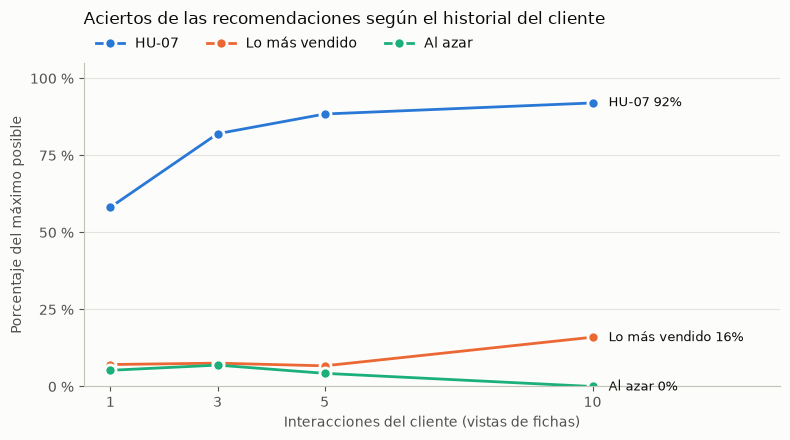

In [9]:
fig, eje = plt.subplots(figsize=(8, 4.5))
finales = del_maximo.iloc[-1].sort_values()
posiciones, anterior = {}, -1
for metodo, valor in finales.items():  # separa las etiquetas finales que quedarían encimadas
    posiciones[metodo] = max(valor, anterior + 0.06)
    anterior = posiciones[metodo]
for metodo, color in COLORES.items():
    eje.plot(del_maximo.index, del_maximo[metodo], color=color, linewidth=2, marker='o', markersize=8,
             markeredgecolor=SUPERFICIE, markeredgewidth=2, label=metodo)
    eje.text(del_maximo.index[-1] + 0.3, posiciones[metodo], f'{metodo} {del_maximo[metodo].iloc[-1]:.0%}',
             va='center', fontsize=9, color=TINTA)
eje.set_xticks(CORTES)
eje.set_xlim(0.5, 13.5)
eje.set_ylim(0, 1.05)
eje.set_yticks([0, 0.25, 0.5, 0.75, 1], ['0 %', '25 %', '50 %', '75 %', '100 %'])
eje.set_xlabel('Interacciones del cliente (vistas de fichas)')
eje.set_ylabel('Porcentaje del máximo posible')
eje.grid(axis='y', color=GRILLA, linewidth=0.8)
eje.set_axisbelow(True)
eje.legend(loc='upper left', frameon=False, ncols=3, bbox_to_anchor=(0, 1.12))
eje.set_title('Aciertos de las recomendaciones según el historial del cliente', loc='left', fontsize=12, pad=28)
plt.tight_layout()
plt.show()

In [10]:
# por plataforma preferida, con 5 interacciones: dónde acierta mejor y peor HU-07
con_historial = resultados[(resultados['interacciones'] == 5) & (resultados['método'] == 'HU-07')]
por_plataforma = con_historial.groupby('plataforma').agg(
    clientes=('cliente', 'nunique'), aciertos=('aciertos', 'sum'), posibles=('aciertos posibles', 'sum'))
por_plataforma['% del máximo'] = (por_plataforma['aciertos'] / por_plataforma['posibles']).map(
    lambda valor: 'sin juegos relevantes por recomendar' if pd.isna(valor) else f'{valor:.0%}')
por_plataforma.sort_values('clientes', ascending=False)

,clientes,aciertos,posibles,% del máximo
plataforma,,,,
PlayStation 5,59,85.0,94.0,90%
Nintendo Switch,51,40.0,48.0,83%
PlayStation 4,31,16.0,17.0,94%
Xbox Series,20,2.0,3.0,67%
PC,17,2.0,2.0,100%
PlayStation 3,8,0.0,0.0,sin juegos relevantes por recomendar
Xbox One,8,0.0,0.0,sin juegos relevantes por recomendar
Nintendo 3DS,6,0.0,0.0,sin juegos relevantes por recomendar


## 3. Conclusiones para el informe

**Coherencia (ficha del producto).** Las recomendaciones de HU-07 comparten el género con el videojuego en
el 73,3 % de los casos, contra 12,6 % de «misma categoría» y 9,9 % de «aleatorios», y comparten plataforma
**y** género en el 48,9 %, contra 12,6 % y 1,8 %. El 100 % comparte plataforma o género (igual que «misma
categoría», que por construcción siempre es de la misma plataforma). A cambio, solo el 75,6 % es de la misma
plataforma (el resto es de la misma familia en su mayoría: 88,5 % comparte familia), por el peso que el IDF
le da al género (ver el notebook del prototipo). La cobertura es del 94,4 %: casi todos los videojuegos
aparecen en alguna recomendación, así que el modelo no concentra las sugerencias en unos pocos productos.

**Precisión con clientes simulados.** Con criterio estricto, HU-07 logra una precision@5 de 31,0 % con una
sola interacción, contra 3,8 % de «lo más vendido» y 2,8 % al azar. Medido como porcentaje del máximo
posible, HU-07 sube de 58,2 % con 1 interacción a 82,0 % con 3, 88,4 % con 5 y 92,0 % con 10, mientras las
alternativas se quedan bajo el 8 % hasta las 5 interacciones. Es decir, **el recomendador aprende la
preferencia del cliente con muy poco historial**: con 3 fichas vistas ya acierta más de 4 de cada 5 veces
que era posible acertar. Con 10 interacciones quedan muy pocos aciertos posibles (25 en total), así que ese
punto es menos confiable, sobre todo para las alternativas.

**Por qué la precisión absoluta baja con el historial.** El catálogo es chico y lo visto en los últimos
7 días no se recomienda, así que los clientes simulados agotan rápido los juegos de su preferencia (el
máximo posible baja de 53,3 % a 2,5 %). En una tienda con un catálogo más grande esta caída sería menor.

**Limitaciones de la evaluación.**

- Los clientes simulados eligen según plataforma y género, los mismos atributos que usa el modelo, así que
  la evaluación confirma que la implementación capta bien preferencias expresadas en esos atributos, no que
  los clientes reales se comporten así. Eso lo medirá el **KPI-05** con clientes reales.
- Las reglas de navegación (70 % / 20 % / 10 %, carrito 25 %, compra 10 %) son supuestos del equipo, no
  datos de Akaispace.
- «Lo más vendido» se calcula con las compras de los mismos clientes simulados, porque la base de prueba
  parte sin ventas.
- Las plataformas con pocos juegos (PS3, Xbox One, 3DS) no dejan juegos relevantes por recomendar después de
  unas pocas vistas, por lo que no se pueden evaluar con este catálogo.

In [11]:
# elimina la base de datos de prueba y vuelve a la de desarrollo
connection.creation.destroy_test_db(nombre_base_desarrollo, verbosity=0)
print('Base de prueba eliminada; conexión de vuelta en', connection.settings_dict['NAME'])

Base de prueba eliminada; conexión de vuelta en db_akaispace
